# 📊 01 — EDA (Exploratory Data Analysis)
> Khảo sát dataset 5 động tác: số video, FPS, duration, phân phối
>
> **Chạy local** — yêu cầu: `opencv-python`, `pandas`, `matplotlib`, `seaborn`

In [1]:
import os
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_theme(style='whitegrid')
print('Libraries loaded OK')

Libraries loaded OK


In [2]:
# ===================== CONFIG =====================
BASE_DIR = r'd:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment'
ARCHIVE_DIR = os.path.join(BASE_DIR, 'archive')
DATA_DIR    = os.path.join(BASE_DIR, 'data', 'processed')
FIG_DIR     = os.path.join(BASE_DIR, 'reports', 'figures')
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR,  exist_ok=True)

LABEL_MAP = {
    0: 'push-up',
    1: 'lateral raise',
    2: 'squat',
    3: 'pull Up',
    4: 'leg raises'
}
COLORS = ['#4f86c6', '#f9b74e', '#50c97b', '#f06060', '#a78bfa']
VIDEO_EXT = ('.mp4', '.avi', '.mov', '.MP4', '.AVI', '.MOV')
print('Config OK')
print('Archive dir:', ARCHIVE_DIR)

Config OK
Archive dir: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\archive


In [3]:
# ===================== SCAN VIDEOS =====================
records = []
for label_id, exercise in LABEL_MAP.items():
    folder = os.path.join(ARCHIVE_DIR, exercise)
    if not os.path.exists(folder):
        print(f'WARNING: folder not found -> {folder}')
        continue
    videos = [f for f in os.listdir(folder) if f.endswith(VIDEO_EXT)]
    for video_file in videos:
        path = os.path.join(folder, video_file)
        cap  = cv2.VideoCapture(path)
        fps         = cap.get(cv2.CAP_PROP_FPS)
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        width       = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height      = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        cap.release()
        duration = frame_count / fps if fps > 0 else 0
        records.append({
            'label_id':    label_id,
            'exercise':    exercise,
            'filename':    video_file,
            'fps':         round(fps, 2),
            'frames':      frame_count,
            'duration_s':  round(duration, 2),
            'width':       width,
            'height':      height,
            'size_mb':     round(os.path.getsize(path) / 1024 / 1024, 2)
        })

df = pd.DataFrame(records)
print(f'Tong video: {len(df)}')
print(df.groupby('exercise')['filename'].count().to_string())

Tong video: 169
exercise
lateral raise    37
leg raises       21
pull Up          26
push-up          56
squat            29


In [4]:
# ===================== SUMMARY STATS =====================
stats = df.groupby('exercise').agg(
    so_video     =('filename',   'count'),
    fps_tb       =('fps',        'mean'),
    fps_min      =('fps',        'min'),
    fps_max      =('fps',        'max'),
    duration_tb  =('duration_s', 'mean'),
    duration_min =('duration_s', 'min'),
    duration_max =('duration_s', 'max'),
    frames_tb    =('frames',     'mean'),
    total_mb     =('size_mb',    'sum')
).reset_index()
stats['fps_tb']      = stats['fps_tb'].round(1)
stats['duration_tb'] = stats['duration_tb'].round(1)
stats['frames_tb']   = stats['frames_tb'].round(0).astype(int)
stats['total_mb']    = stats['total_mb'].round(1)

print('\n=== THONG KE TONG QUAN ===')
print(stats[['exercise','so_video','fps_tb','fps_min','fps_max','duration_tb','total_mb']].to_string(index=False))
print(f'\nTong tat ca: {len(df)} video | {df["duration_s"].sum():.0f}s | {df["size_mb"].sum():.0f} MB')


=== THONG KE TONG QUAN ===
     exercise  so_video  fps_tb  fps_min  fps_max  duration_tb  total_mb
lateral raise        37    26.1    23.98    29.98          8.3     422.7
   leg raises        21    28.4    23.98    29.98          9.0     225.9
      pull Up        26    29.7    23.98    60.00          8.1     140.0
      push-up        56    30.0    29.97    29.97          5.9      68.6
        squat        29    27.2    23.98    29.97         10.2     464.5

Tong tat ca: 169 video | 1335s | 1322 MB


In [5]:
# ===================== FPS ANALYSIS =====================
print('Phan phoi FPS:')
print(df['fps'].value_counts().sort_index())
print()
print('FPS unique:', sorted(df['fps'].unique()))

Phan phoi FPS:
fps
23.98     26
24.00     18
25.00      6
29.97    114
29.98      2
30.00      2
60.00      1
Name: count, dtype: int64

FPS unique: [np.float64(23.98), np.float64(24.0), np.float64(25.0), np.float64(29.97), np.float64(29.98), np.float64(30.0), np.float64(60.0)]


C:\Users\Admin\AppData\Local\Temp\ipykernel_9036\2095331498.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_class, labels=[ex[:10] for ex in exercises], patch_artist=True)


Saved: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\reports\figures\eda_overview.png


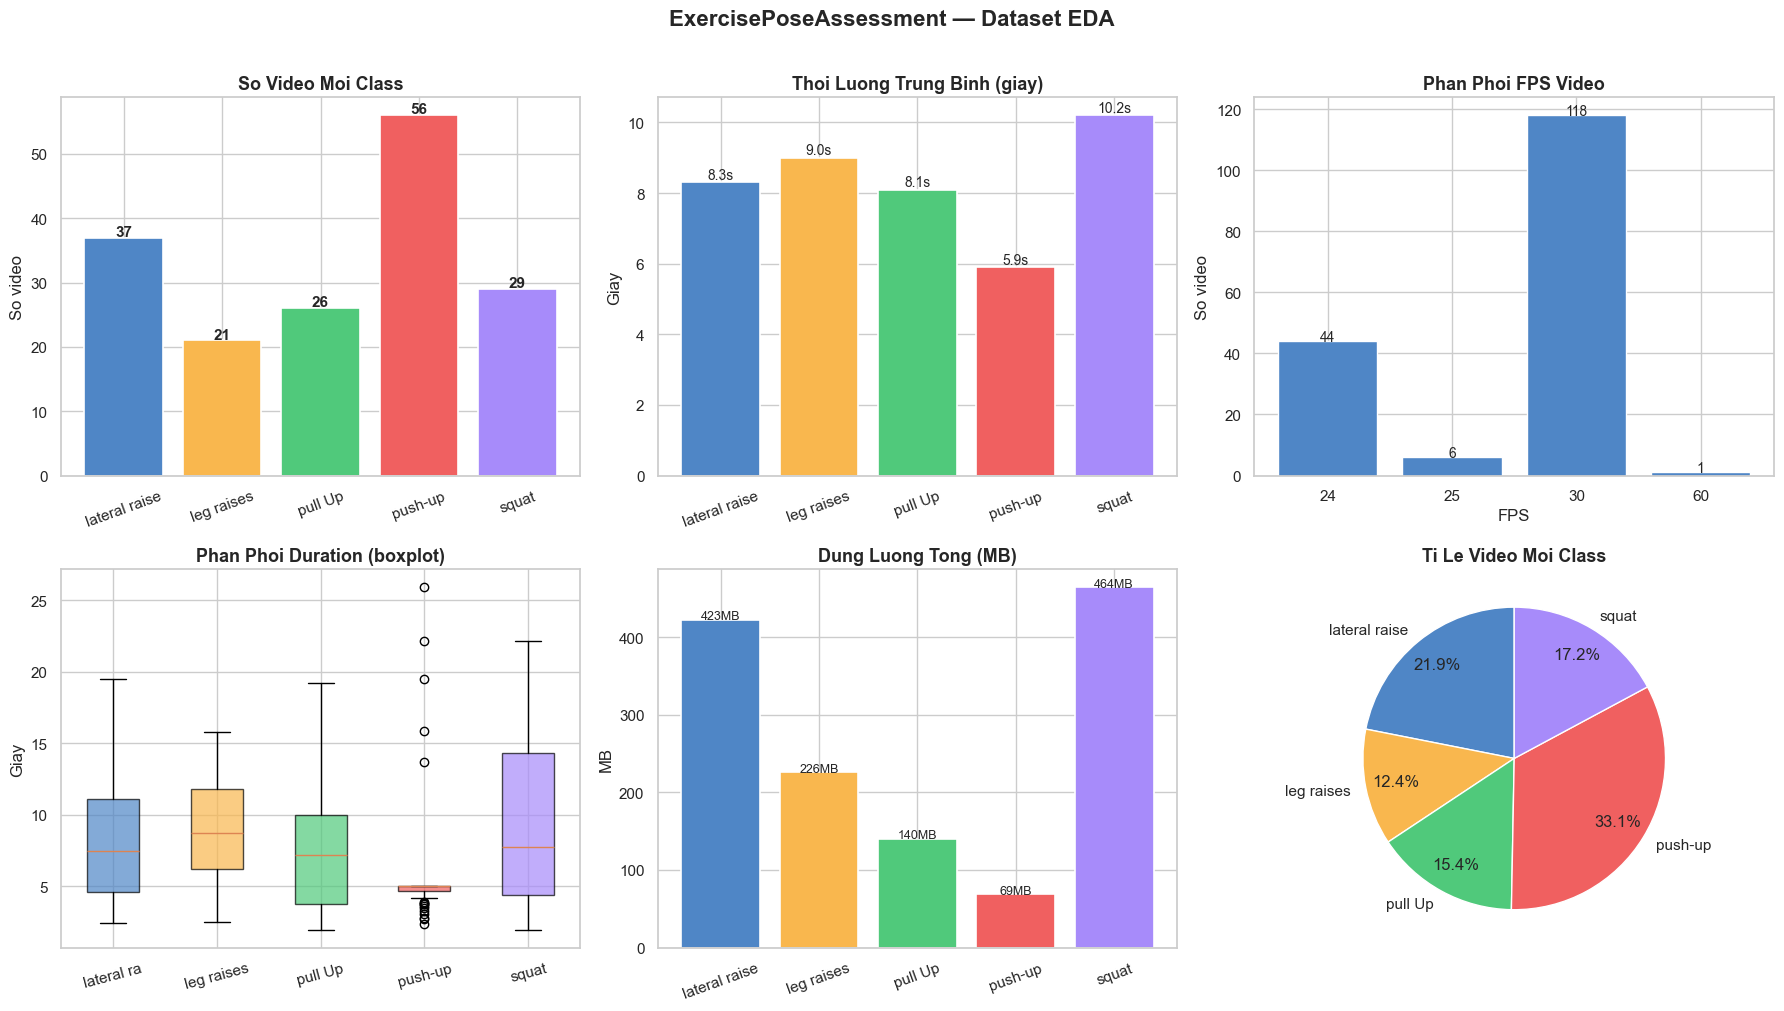

In [6]:
# ===================== VISUALIZATION =====================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('ExercisePoseAssessment — Dataset EDA', fontsize=16, fontweight='bold', y=1.01)

exercises = stats['exercise'].tolist()

# 1. So video moi class
ax = axes[0, 0]
bars = ax.bar(exercises, stats['so_video'], color=COLORS, edgecolor='white', linewidth=1.2)
ax.set_title('So Video Moi Class', fontsize=13, fontweight='bold')
ax.set_ylabel('So video')
ax.tick_params(axis='x', rotation=20)
for bar, v in zip(bars, stats['so_video']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, str(v),
            ha='center', fontsize=11, fontweight='bold')

# 2. Duration trung binh
ax = axes[0, 1]
bars = ax.bar(exercises, stats['duration_tb'], color=COLORS, edgecolor='white', linewidth=1.2)
ax.set_title('Thoi Luong Trung Binh (giay)', fontsize=13, fontweight='bold')
ax.set_ylabel('Giay')
ax.tick_params(axis='x', rotation=20)
for bar, v in zip(bars, stats['duration_tb']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, f'{v:.1f}s',
            ha='center', fontsize=10)

# 3. Phan phoi FPS
ax = axes[0, 2]
fps_counts = df['fps'].round().astype(int).value_counts().sort_index()
ax.bar(fps_counts.index.astype(str), fps_counts.values, color='#4f86c6', edgecolor='white')
ax.set_title('Phan Phoi FPS Video', fontsize=13, fontweight='bold')
ax.set_xlabel('FPS')
ax.set_ylabel('So video')
for i, (fps_val, count) in enumerate(fps_counts.items()):
    ax.text(i, count + 0.2, str(count), ha='center', fontsize=10)

# 4. Duration boxplot
ax = axes[1, 0]
data_by_class = [df[df['exercise'] == ex]['duration_s'].values for ex in exercises]
bp = ax.boxplot(data_by_class, labels=[ex[:10] for ex in exercises], patch_artist=True)
for patch, color in zip(bp['boxes'], COLORS):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_title('Phan Phoi Duration (boxplot)', fontsize=13, fontweight='bold')
ax.set_ylabel('Giay')
ax.tick_params(axis='x', rotation=15)

# 5. Dung luong tung class
ax = axes[1, 1]
bars = ax.bar(exercises, stats['total_mb'], color=COLORS, edgecolor='white', linewidth=1.2)
ax.set_title('Dung Luong Tong (MB)', fontsize=13, fontweight='bold')
ax.set_ylabel('MB')
ax.tick_params(axis='x', rotation=20)
for bar, v in zip(bars, stats['total_mb']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f'{v:.0f}MB',
            ha='center', fontsize=9)

# 6. Pie chart
ax = axes[1, 2]
ax.pie(stats['so_video'], labels=exercises, colors=COLORS,
       autopct='%1.1f%%', startangle=90, pctdistance=0.8)
ax.set_title('Ti Le Video Moi Class', fontsize=13, fontweight='bold')

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, 'eda_overview.png')
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
print(f'Saved: {fig_path}')
plt.show()

In [7]:
# ===================== SAVE eda_stats.json =====================
eda_stats = {
    'total_videos': int(len(df)),
    'total_duration_sec': round(float(df['duration_s'].sum()), 1),
    'total_size_mb': round(float(df['size_mb'].sum()), 1),
    'fps_note': 'Chuan hoa ve 30fps truoc khi extract keypoints',
    'classes': []
}
for _, row in stats.iterrows():
    eda_stats['classes'].append({
        'label_id':       int(list(LABEL_MAP.keys())[list(LABEL_MAP.values()).index(row['exercise'])]),
        'exercise':       row['exercise'],
        'video_count':    int(row['so_video']),
        'avg_fps':        float(row['fps_tb']),
        'avg_duration_s': float(row['duration_tb']),
        'avg_frames':     int(row['frames_tb']),
        'total_size_mb':  float(row['total_mb'])
    })

out_path = os.path.join(DATA_DIR, 'eda_stats.json')
with open(out_path, 'w', encoding='utf-8') as f:
    json.dump(eda_stats, f, indent=2, ensure_ascii=False)
print(f'Saved: {out_path}')
print(json.dumps(eda_stats, indent=2, ensure_ascii=False))

Saved: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\data\processed\eda_stats.json
{
  "total_videos": 169,
  "total_duration_sec": 1335.0,
  "total_size_mb": 1321.8,
  "fps_note": "Chuan hoa ve 30fps truoc khi extract keypoints",
  "classes": [
    {
      "label_id": 1,
      "exercise": "lateral raise",
      "video_count": 37,
      "avg_fps": 26.1,
      "avg_duration_s": 8.3,
      "avg_frames": 226,
      "total_size_mb": 422.7
    },
    {
      "label_id": 4,
      "exercise": "leg raises",
      "video_count": 21,
      "avg_fps": 28.4,
      "avg_duration_s": 9.0,
      "avg_frames": 259,
      "total_size_mb": 225.9
    },
    {
      "label_id": 3,
      "exercise": "pull Up",
      "video_count": 26,
      "avg_fps": 29.7,
      "avg_duration_s": 8.1,
      "avg_frames": 257,
      "total_size_mb": 140.0
    },
    {
      "label_id": 0,
      "exercise": "push-up",
      "video_count": 56,
      "avg_fps": 30.0,
      "avg_duration_s": 5.